# Model experiments and frozen evaluation
Training uses customer-disjoint partitions and five-fold training-only validation. The selected model and threshold were frozen before final test evaluation. Re-reading saved results does not refit any model.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
import json
selection = json.loads((root / 'models_artifacts/selection.json').read_text())
display({'selected_model': selection['model'], 'threshold': selection['threshold'], 'rule': selection['selection_rule']})
display(pd.read_csv(root / 'docs/model_comparison.csv'))
log = pd.read_csv(root / 'models_artifacts/experiment_log.csv')
display(log.groupby(['model','phase']).training_seconds.agg(['count','sum']))

{'selected_model': 'lightgbm',
 'threshold': 0.25,
 'rule': 'Highest validation ROC-AUC, then recall; threshold chosen on validation only'}

,Unnamed: 0,accuracy,precision,recall,f1,roc_auc,threshold
0,xgboost,0.739796,0.717857,0.897321,0.797619,0.803047,0.35
1,lightgbm,0.711735,0.679612,0.937500,0.787992,0.800183,0.25
2,random_forest,0.742347,0.746988,0.830357,0.786469,0.798669,0.45
3,logistic,0.727041,0.715867,0.866071,0.783838,0.794915,0.35
4,ann,0.720663,0.699825,0.895089,0.785504,0.794776,0.30
5,decision_tree,0.688776,0.655488,0.959821,0.778986,0.782413,0.20
6,knn,0.698980,0.673203,0.919643,0.777358,0.778533,0.35


count        sum
model         phase                             
ann           cross_validation      5   5.972388
              test                  1   0.000000
              validation            1   1.306851
autoencoder   test                  1   0.000000
              validation            1   3.927057
clv           cross_validation      5   8.299571
              test                  1   0.000000
              validation            1   2.080641
decision_tree cross_validation      5   0.116301
              test                  1   0.000000
              validation            1   0.027095
knn           cross_validation      5   0.055743
              test                  1   0.000000
              validation            1   0.011836
lightgbm      cross_validation      5   0.317499
              test                  1   0.000000
              validation            1   0.068358
logistic      cross_validation      5   0.117529
              test                  1   0.000000
              validation            1   0.025597
lstm          cross_validation      5  30.090362
              test                  1   0.000000
              validation            1   5.975795
random_forest cross_validation     10   3.650147
              test                  1   0.000000
              validation            1   0.552585
xgboost       cross_validation     10   1.265116
              test                  1   0.000000
              validation            1   0.146197

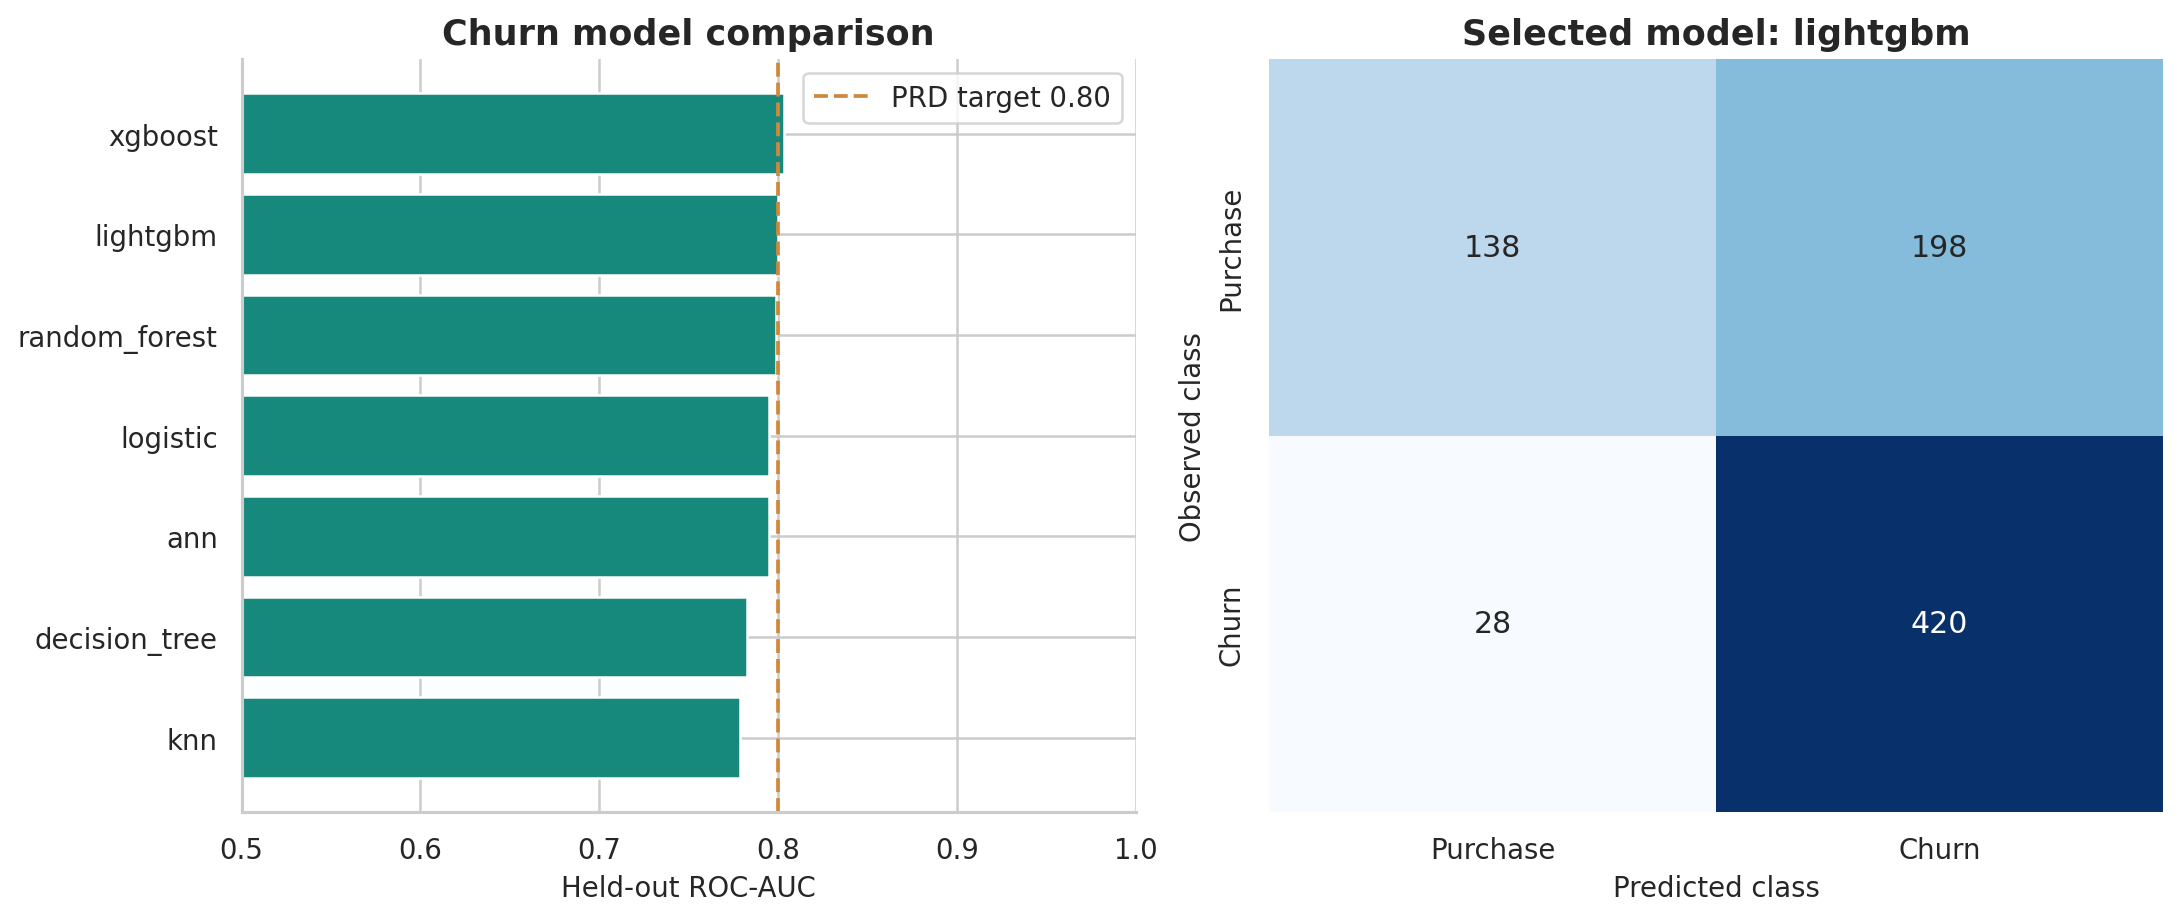

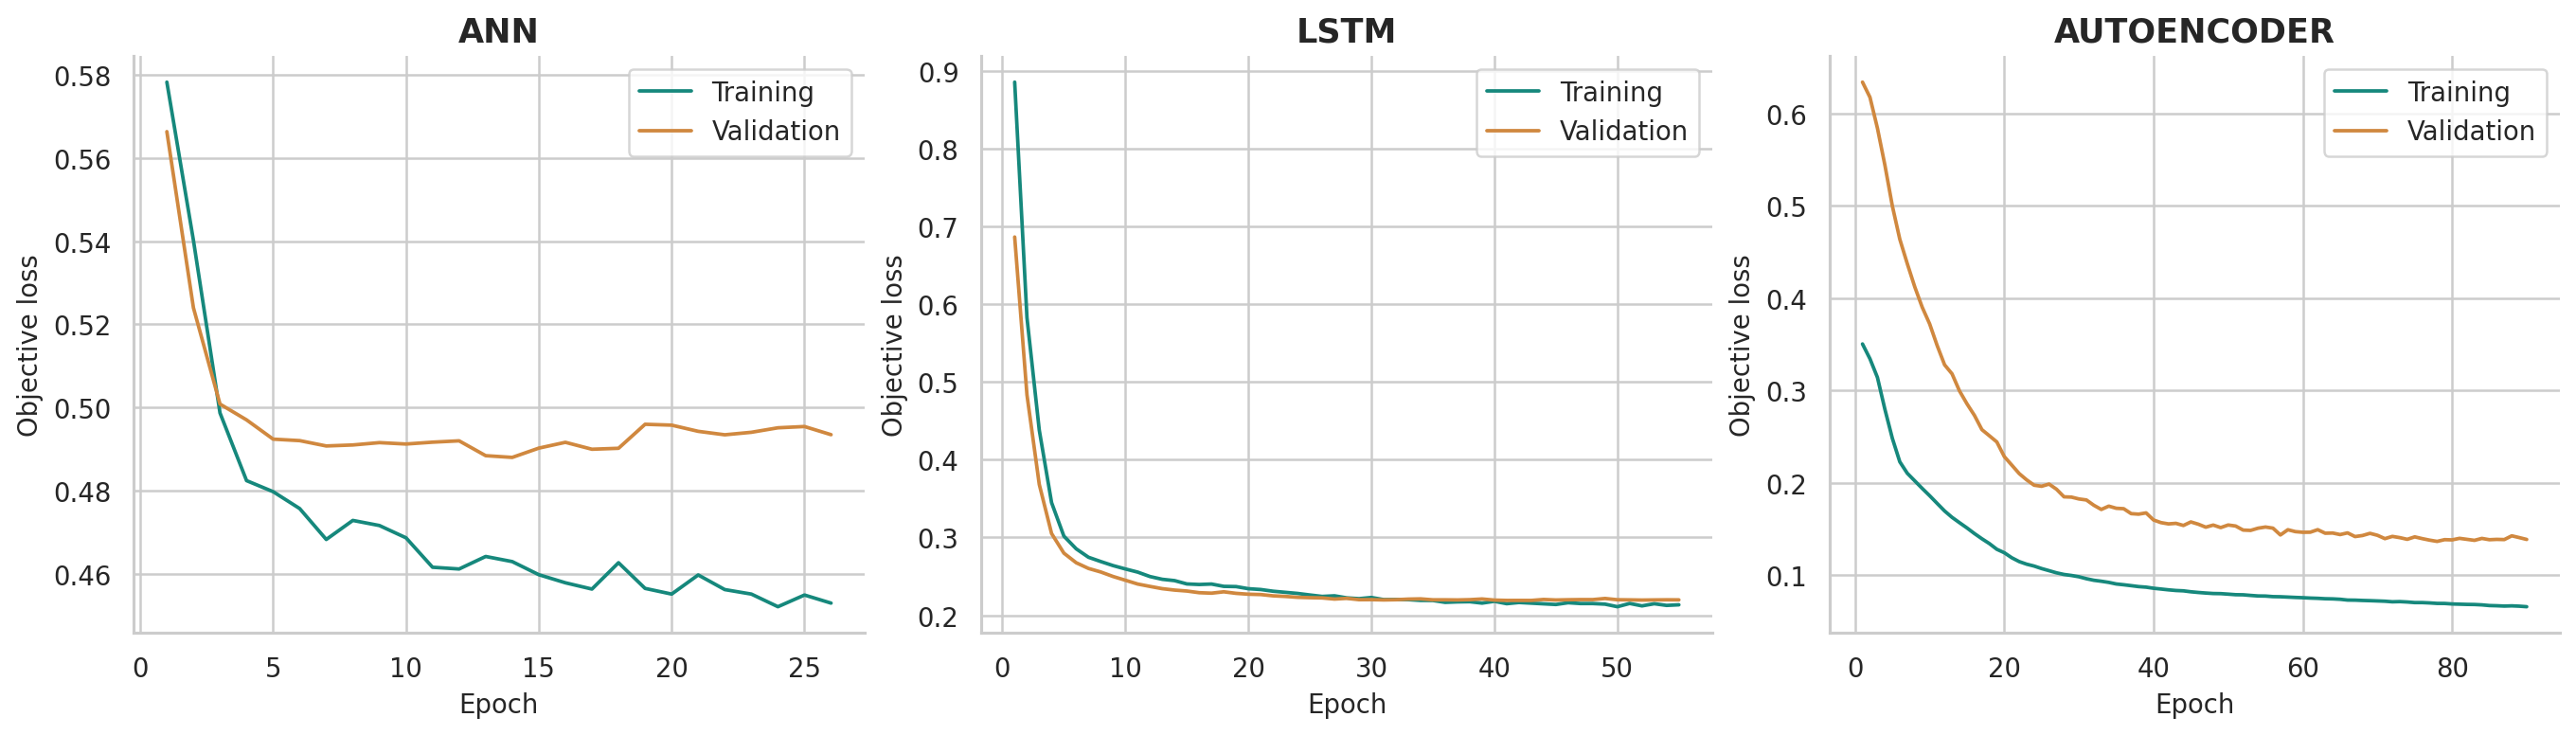

,algorithm,k,silhouette,davies_bouldin
0,K-Means,3,0.440684,0.794834
1,Gaussian mixture,3,0.192803,2.641039


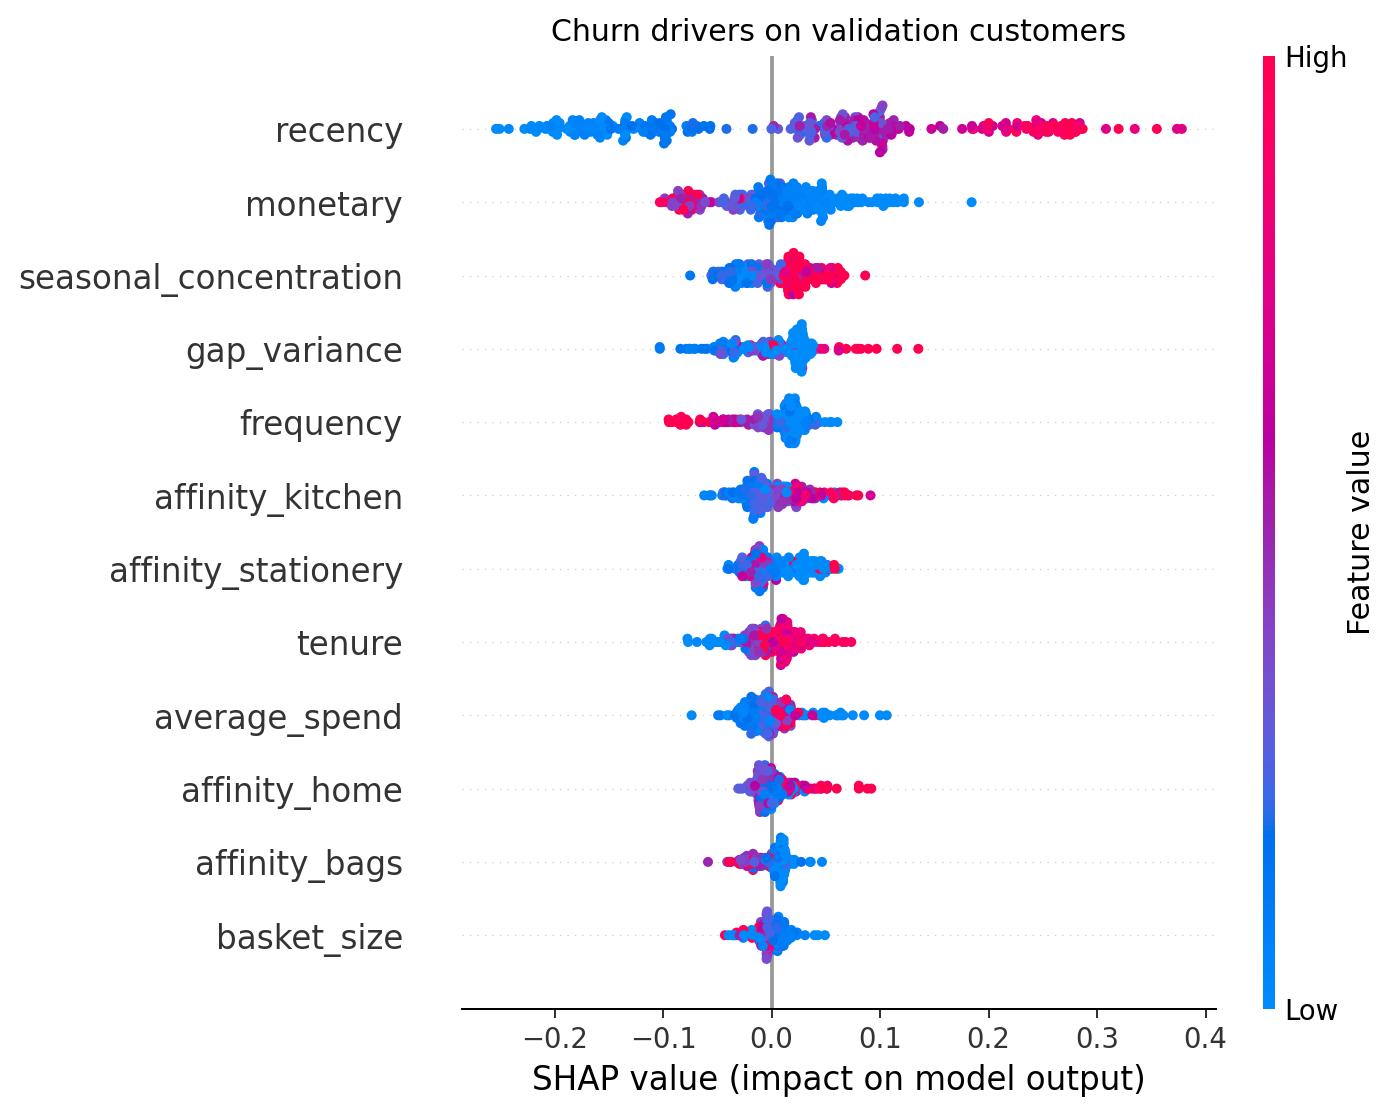

In [2]:
display(Image(filename=str(root / 'docs/model_evaluation.png')))
display(Image(filename=str(root / 'docs/neural_loss_curves.png')))
display(pd.read_csv(root / 'models_artifacts/cluster_metrics.csv'))
display(Image(filename=str(root / 'docs/shap_summary.png')))

## Interpretation
Use the final report for actual target status. LSTM timing is capped at 90 days; no-purchase customers have a censored target at that cap. Autoencoder flags are candidates for review, not confirmed fraud. Validation determines model selection; test results must not guide further tuning in this run.